# Práctica de Clustering

Integrantes del grupo:

- Anton Pogromskyy Mozharsky (anton.pogromskyy@alumnos.upm.es)
- Diego Mateo Fernandez (diego.mateofer@alumnos.upm.es)
- Oliver Anderson Llorens (oliver.anderson@alumnos.upm.es)

En esta práctica, aplicaremos los conceptos de clustering impartidos en un dataset de nuestra elección.

## Exploración de los datos

Primero, cargamos el archivo con los datos para analizarlo. En este trabajo utilizamos el dataset [Customer Personality Analysis](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis), publicado en Kaggle. 

El objetivo es explorar si existen grupos de clientes con comportamientos de compra similares.

In [1]:
import pandas as pd

df = pd.read_csv("data/marketing_campaign.csv", sep="\t")

print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
df.head()

Filas: 2240 | Columnas: 29


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


Contiene 2.240 registros y 29 variables. Cada fila representa a un cliente e incluye información sobre su perfil demográfico, sus hábitos de compra y su respuesta a campañas de marketing.


| Columna o grupo | Significado |
| --- | --- |
| `ID` | Identificador del cliente. |
| `Year_Birth` | Año de nacimiento. |
| `Education`, `Marital_Status` | Nivel educativo y estado civil, respectivamente. |
| `Income` | Ingresos anuales del hogar. |
| `Kidhome`, `Teenhome` | Número de niños y adolescentes en el hogar, respectivamente. |
| `Dt_Customer` | Fecha de alta como cliente. |
| `Recency` | Días transcurridos desde la última compra. |
| `Mnt*` | Importe gastado en los últimos dos años por categoría. El sufijo indica el producto, como `Wines` para vino o `Fruits` para fruta. |
| `NumDealsPurchases` | Número de compras realizadas con descuento. |
| `NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases` | Número de compras por web, catálogo y tienda física, respectivamente. |
| `NumWebVisitsMonth` | Número de visitas a la web de la empresa en el último mes. |
| `AcceptedCmp1` a `AcceptedCmp5` | Indican si el cliente aceptó la oferta de cada campaña numerada (1 = sí, 0 = no). |
| `Complain` | Indica si el cliente presentó alguna reclamación en los últimos dos años (1 = sí, 0 = no). |
| `Z_CostContact`, `Z_Revenue` | Sus nombres hacen referencia al coste de contacto y a los ingresos, respectivamente. La ficha del dataset no explica cómo se definen. |
| `Response` | Indica si el cliente aceptó la oferta de la última campaña (1 = sí, 0 = no). |

In [2]:
resumen_columnas = pd.DataFrame({
    "tipo": df.dtypes,
    "valores_ausentes": df.isna().sum(),
    "valores_distintos": df.nunique()
})

resumen_columnas

,tipo,valores_ausentes,valores_distintos
ID,int64,0,2240
Year_Birth,int64,0,59
Education,str,0,5
Marital_Status,str,0,8
Income,float64,24,1974
Kidhome,int64,0,3
Teenhome,int64,0,3
Dt_Customer,str,0,663
Recency,int64,0,100
MntWines,int64,0,776


De primeras, observamos que `Income` es la única variable que tiene valores ausentes. Al ser relativamente pocos, deberíamos ver cómo tratarlos de usar la variable. `ID` identifica a cada fila, con lo que lo conservaremos para identificar los registros pero debemos de eliminarlo a la hora de hacer clustering. `Z_CostContact` y `Z_Revenue` son constantes, por lo que podemos excluirlas. `Dt_Customer` es una fecha, pero se ha leído como texto, por lo que tenemos que convertirla a formato fecha. Por último, vemos como la variable que usaremos como predicción es `Response`.

In [3]:
columnas_excluir = ["ID", "Z_CostContact", "Z_Revenue"]

resumen_numerico = (
    df.drop(columns=columnas_excluir)
    .select_dtypes(include="number")
    .describe()
    .T
    .round(2)
)

resumen_numerico

,count,mean,std,min,25%,50%,75%,max
Year_Birth,2240.0,1968.81,11.98,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.25,25173.08,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.44,0.54,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.51,0.54,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.11,28.96,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.94,336.60,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.30,39.77,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.95,225.72,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.53,54.63,0.0,3.00,12.0,50.00,259.0
MntSweetProducts,2240.0,27.06,41.28,0.0,1.00,8.0,33.00,263.0


Excluímos el ID y las constantes, y analizamos el comportamiento estadístico de las demás variables. Lo que destaca es el `Income`, que tiene un máximo de 666.666, pero su tercer cuartil es 68.522. El mínimo en `Year_Birth` es 1893, por lo que habría que mirar si existen casos de este tipo y como tratarlos, ya que al ser el dataset va desde 2012 a 2014, por lo que no es del todo imposible que alguien de ese año se registrase, pero si sería muy raro.

In [4]:
columnas_revision = [
    "ID", "Year_Birth", "Dt_Customer", "Income",
    "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"
]

print("Los cinco ingresos más altos")
display(df.nlargest(5, "Income")[columnas_revision])

print("Los cinco años de nacimiento más antiguos")
display(df.nsmallest(5, "Year_Birth")[columnas_revision])

Los cinco ingresos más altos


,ID,Year_Birth,Dt_Customer,Income,NumWebPurchases,NumCatalogPurchases,NumStorePurchases
2233,9432,1977,02-06-2013,666666.0,3,1,3
617,1503,1976,03-06-2013,162397.0,0,0,1
687,1501,1982,04-08-2012,160803.0,0,28,1
1300,5336,1971,04-06-2013,157733.0,1,0,1
164,8475,1973,01-03-2014,157243.0,0,22,0


Los cinco años de nacimiento más antiguos


,ID,Year_Birth,Dt_Customer,Income,NumWebPurchases,NumCatalogPurchases,NumStorePurchases
239,11004,1893,17-05-2014,60182.0,1,0,2
339,1150,1899,26-09-2013,83532.0,4,6,4
192,7829,1900,26-09-2013,36640.0,2,1,2
1950,6663,1940,08-07-2013,51141.0,3,1,4
424,6932,1941,13-04-2013,93027.0,7,10,5


Vemos que el ingreso más alto es cuatro veces mayor aproximadamente al segundo más alto. Es un caso aislado que conviene tener en cuenta. Tenemos registros de fecha de nacimiento den 1893, 1899 y 1900, que implica edades superiores a 110 años. El siguiente cliente más antiguo es 1940, por lo que los tres valores anteriores son poco plausibles. Vemos que hay clientes con un numero elevado de compras de catálogo (28, 22, 10) frente a la mediana (2). Esto es importante para darse cuenta de como los métodos de clustering podrían estar en un futuro agrupando los datos.

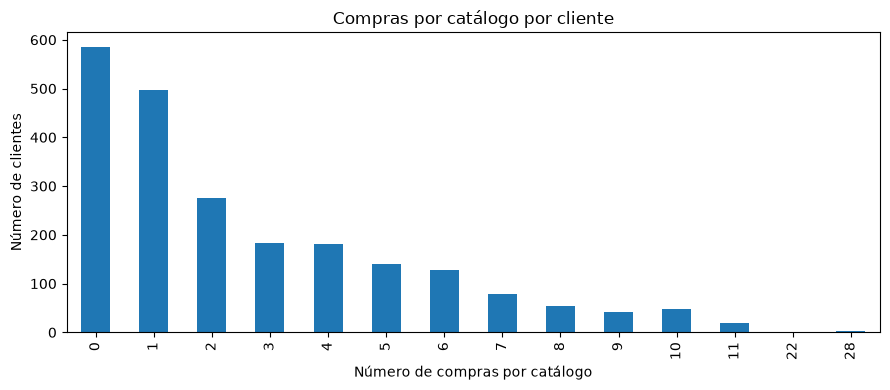

In [5]:
import matplotlib.pyplot as plt

compras_catalogo = df["NumCatalogPurchases"]

compras_catalogo.value_counts().sort_index().plot.bar(figsize=(9, 4))
plt.xlabel("Número de compras por catálogo")
plt.ylabel("Número de clientes")
plt.title("Compras por catálogo por cliente")
plt.tight_layout()
plt.show()

La mayoría de clientes están entre 0 y 2 compras, y los valores altos de 22 y 28 aparecen de forma aislada, pero no dejan de ser válidos, lo que habrá que comprobar como influyen.

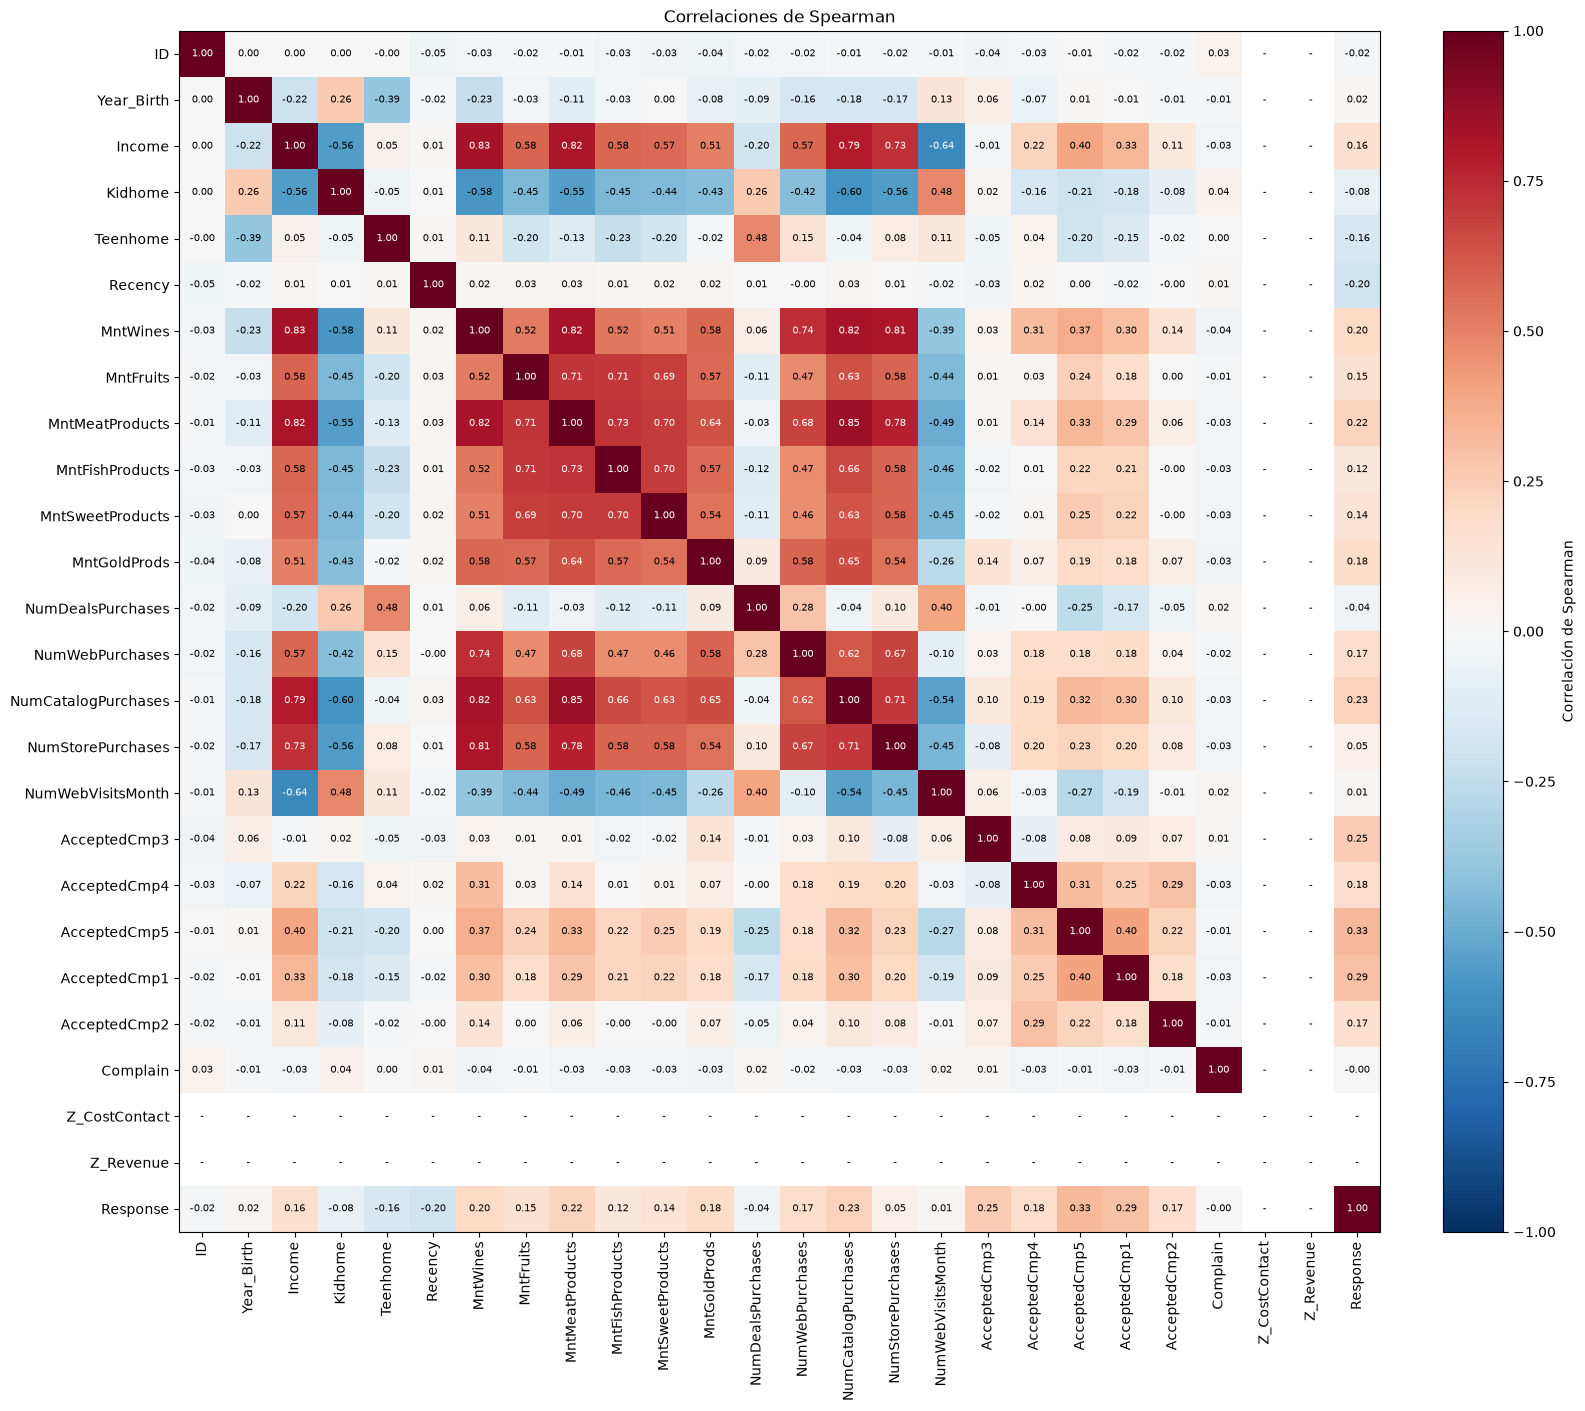

In [6]:
import matplotlib.pyplot as plt

variables_numericas = df.select_dtypes(include="number")
correlaciones = variables_numericas.corr(method="spearman")

fig, ax = plt.subplots(figsize=(16, 14), layout="constrained")
imagen = ax.imshow(correlaciones.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(correlaciones.columns)), correlaciones.columns, rotation=90)
ax.set_yticks(range(len(correlaciones.index)), correlaciones.index)
ax.set_title("Correlaciones de Spearman")
fig.colorbar(imagen, ax=ax, label="Correlación de Spearman")

for fila, valores in enumerate(correlaciones.to_numpy()):
    for columna, valor in enumerate(valores):
        etiqueta = "-" if pd.isna(valor) else f"{valor:.2f}"
        ax.text(
            columna, fila, etiqueta,
            ha="center", va="center",
            color="white" if abs(valor) > 0.6 else "black",
            fontsize=7,
        )

plt.show()

Al ser un heatmap tan grande es difícil poder interpretarla bien, pero podemos ver que en la actividad de compra, los clientes con mayores ingresos tienden a gastar mas, y quienes compran por catálogo o tienda también tienden a gastar más. La recencia tiene correlaciones débiles con el resto, y las visitas a la web se relacionan negativamente con los ingresos y compras por catálogo.

## Preprocesado de los datos

Para preparar los datos del clustering, excluimos las filas sin Income y los tres registros con años de nacimiento poco plausibles (1893, 1899 y 1900). También retiramos ID y las columnas constantes, y reservamos Response para comparar la aceptación de la campaña entre los grupos.

Conservamos el ingreso de 666.666 porque, aunque es atípico, puede ser válido.

In [7]:
columnas_excluir = ["ID", "Z_CostContact", "Z_Revenue", "Response"]

df_clustering = df.dropna(subset=["Income"])
df_clustering = df_clustering.loc[
    ~df_clustering["Year_Birth"].isin([1893, 1899, 1900])
].copy()

X = df_clustering.drop(columns=columnas_excluir)

print(f"Clientes: {X.shape[0]} | Variables candidatas: {X.shape[1]}")
X.head()

Clientes: 2213 | Variables candidatas: 25


,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain
0,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,...,8,10,4,7,0,0,0,0,0,0
1,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,...,1,1,2,5,0,0,0,0,0,0
2,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,...,8,2,10,4,0,0,0,0,0,0
3,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,...,2,0,4,6,0,0,0,0,0,0
4,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,...,5,3,6,5,0,0,0,0,0,0


Vamos a preparar la fecha.

In [8]:
fechas_alta = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
fecha_referencia = fechas_alta.max()

X["AntiguedadDias"] = (fecha_referencia - fechas_alta).dt.days
X = X.drop(columns="Dt_Customer", errors="ignore")

print(f"Fecha de referencia: {fecha_referencia:%d/%m/%Y}")
X[["AntiguedadDias"]].head()

Fecha de referencia: 29/06/2014


,AntiguedadDias
0,663
1,113
2,312
3,139
4,161


Como hemos visto, tenemos variables categóricas. Hace falta codificarlas en variables númericas, usando One-hot. Las variables que manipularemos serán educación y estado civil.

In [ ]:
columnas_categoricas = ["Education", "Marital_Status"]

X_codificado = pd.get_dummies(X, columns=columnas_categoricas, dtype=int)

X_codificado.filter(regex=r"^(Education|Marital_Status)_").head()

,Education_2n Cycle,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,0,0,1,0,0,0,0,0,0,1,0,0,0
1,0,0,1,0,0,0,0,0,0,1,0,0,0
2,0,0,1,0,0,0,0,0,0,0,1,0,0
3,0,0,1,0,0,0,0,0,0,0,1,0,0
4,0,0,0,0,1,0,0,0,1,0,0,0,0


Los ingresos, los días y los recuentos de compras tienen escalas distintas. Por eso estandarizamos las variables numéricas con StandardScaler. En el caso de Income, aplicamos primero log1p para comprimir los valores más altos y reducir su influencia en las distancias entre clientes.

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler

columnas_numericas = X.select_dtypes(include="number").columns
columnas_escalar = [
    columna for columna in columnas_numericas
    if X[columna].nunique() > 2
]

X_preprocesado = X_codificado.copy()
X_preprocesado["Income"] = np.log1p(X_preprocesado["Income"])

escalador = StandardScaler()
X_preprocesado[columnas_escalar] = escalador.fit_transform(X_preprocesado[columnas_escalar])

X_preprocesado[columnas_escalar].head().round(2)

,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AntiguedadDias
0,-1.02,0.43,-0.82,-0.93,0.31,0.98,1.55,1.69,2.45,1.48,0.85,0.35,1.43,2.50,-0.56,0.69,1.53
1,-1.28,-0.02,1.04,0.91,-0.38,-0.87,-0.64,-0.72,-0.65,-0.63,-0.73,-0.17,-1.13,-0.57,-1.17,-0.13,-1.19
2,-0.33,0.84,-0.82,-0.93,-0.80,0.36,0.57,-0.18,1.34,-0.15,-0.04,-0.69,1.43,-0.23,1.29,-0.55,-0.21
3,1.29,-1.11,1.04,-0.93,-0.80,-0.87,-0.56,-0.66,-0.50,-0.59,-0.75,-0.17,-0.76,-0.91,-0.56,0.28,-1.06
4,1.03,0.43,1.04,-0.93,1.55,-0.39,0.42,-0.22,0.15,-0.00,-0.56,1.39,0.33,0.11,0.06,-0.13,-0.95


Como hemos observado a lo largo de la práctica, hay una gran cantidad de variables, por lo que sería interesante reducirlas. Además, tenemos variables correlacionadas, por lo que emplearemos un algoritmo de FSS (Feature Subset Selection) para reducir el número de variables. En este caso, probamos SBS (Sequential Backward Selection), usando K-means para comparar los subconjuntos. También usaremos el silhouette score para guiar la búsqueda. Fijamos k=5 de manera arbitraria. 

In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_sbs = 5

bloques = {}
for variable in X.columns:
    if variable in columnas_categoricas:
        bloques[variable] = [
            columna for columna in X_preprocesado.columns
            if columna.startswith(f"{variable}_")
        ]
    else:
        bloques[variable] = [variable]


def evaluar_subconjunto(variables):
    columnas = [
        columna
        for variable in variables
        for columna in bloques[variable]
    ]
    datos = X_preprocesado[columnas]

    if len(datos.drop_duplicates()) < k_sbs:
        return float("-inf")

    modelo = KMeans(n_clusters=k_sbs, n_init=10, random_state=42)
    etiquetas = modelo.fit_predict(datos)

    if pd.Series(etiquetas).nunique() < k_sbs:
        return float("-inf")

    return silhouette_score(X_preprocesado, etiquetas)


seleccionadas = list(bloques)
puntuacion_actual = evaluar_subconjunto(seleccionadas)

historial = [{
    "variable_retirada": "Ninguna (punto de partida)",
    "variables_restantes": len(seleccionadas),
    "silhouette_referencia": puntuacion_actual,
}]

while len(seleccionadas) > 1:
    puntuaciones = {
        variable: evaluar_subconjunto([v for v in seleccionadas if v != variable])
        for variable in seleccionadas
    }

    mejor_retirada = max(puntuaciones, key=puntuaciones.get)
    mejor_puntuacion = puntuaciones[mejor_retirada]

    if mejor_puntuacion <= puntuacion_actual:
        break

    seleccionadas.remove(mejor_retirada)
    puntuacion_actual = mejor_puntuacion
    historial.append({
        "variable_retirada": mejor_retirada,
        "variables_restantes": len(seleccionadas),
        "silhouette_referencia": puntuacion_actual,
    })

print(f"Clientes evaluados: {len(X_preprocesado)}")
print(f"Variables conservadas: {len(seleccionadas)} de {len(bloques)}")
print(", ".join(seleccionadas))
pd.DataFrame(historial).round(4)

Clientes evaluados: 2213
Variables conservadas: 14 de 25
Education, Marital_Status, Income, MntWines, MntFruits, MntSweetProducts, MntGoldProds, NumDealsPurchases, NumWebPurchases, NumWebVisitsMonth, AcceptedCmp5, AcceptedCmp1, AcceptedCmp2, Complain


,variable_retirada,variables_restantes,silhouette_referencia
0,Ninguna (punto de partida),25,0.1147
1,Teenhome,24,0.1235
2,Recency,23,0.1236
3,NumCatalogPurchases,22,0.1271
4,NumStorePurchases,21,0.1333
5,MntMeatProducts,20,0.1368
6,MntFishProducts,19,0.1457
7,Year_Birth,18,0.1480
8,AntiguedadDias,17,0.1563
9,Kidhome,16,0.1630


Con k = 5, SBS conservó 14 de las 25 variables candidatas. El silhouette de referencia pasó de 0,1144 a 0,1556. Por ello, vamos a probar con los dos conjuntos ya que la diferencia no es tanta como para que descartemos el conjunto de las 25 variables.

## Análisis de clustering

Lo primero que haremos es comparar K-means con distintos valores de K, para los dos conjuntos de variables que tenemos. En este caso, probaremos de 2 a 8 clusters.

In [26]:
conjuntos = {
    "25 candidatas": list(bloques),
    "14 seleccionadas por SBS": seleccionadas,
}

resultados_k = []

for nombre, variables in conjuntos.items():
    columnas = [
        columna
        for variable in variables
        for columna in bloques[variable]
    ]
    datos_modelo = X_preprocesado[columnas]

    for k in range(2, 9):
        modelo = KMeans(n_clusters=k, n_init=10, random_state=42)
        etiquetas = modelo.fit_predict(datos_modelo)
        tamanos = pd.Series(etiquetas).value_counts()

        resultados_k.append({
            "conjunto": nombre,
            "k": k,
            "inercia": modelo.inertia_,
            "silhouette_referencia": silhouette_score(
                X_preprocesado, etiquetas
            ),
            "clientes_grupo_menor": tamanos.min(),
        })

tabla_k = pd.DataFrame(resultados_k)
tabla_k.round({"inercia": 1, "silhouette_referencia": 4})

,conjunto,k,inercia,silhouette_referencia,clientes_grupo_menor
0,25 candidatas,2,30551.6,0.2541,933
1,25 candidatas,3,27202.1,0.1895,596
2,25 candidatas,4,25719.1,0.1225,534
3,25 candidatas,5,24718.4,0.1147,273
4,25 candidatas,6,23785.6,0.1142,190
5,25 candidatas,7,23100.0,0.1023,188
6,25 candidatas,8,22552.2,0.1040,174
7,14 seleccionadas por SBS,2,15317.7,0.2485,943
8,14 seleccionadas por SBS,3,13251.5,0.1873,556
9,14 seleccionadas por SBS,4,12239.3,0.1661,291


Vemos que la tabla nos indica que la mejor k es 2 en ambos conjuntos. El mayor silhouette lo conseguimos usando todas las variables, pero es solo ligeramente superior al de usando 14. Antes de elegir, veamos que aporta el método del codo.

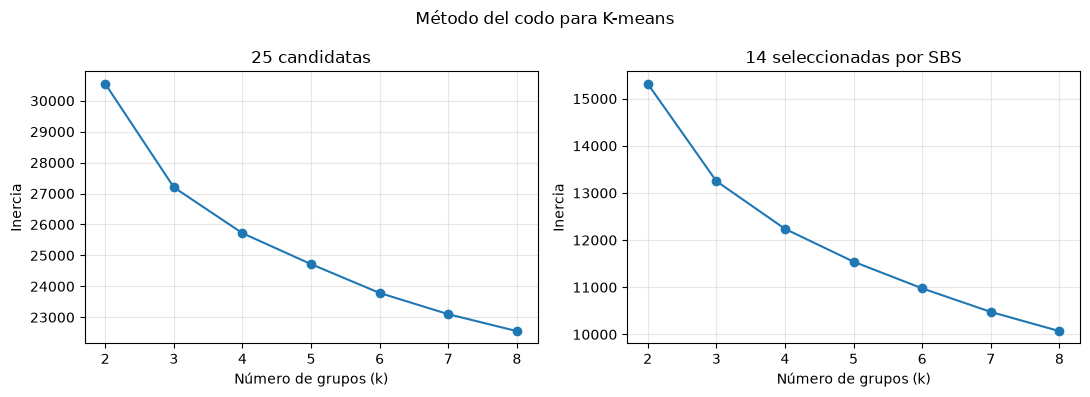

In [28]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

for eje, (nombre, resultados) in zip(
    ejes, tabla_k.groupby("conjunto", sort=False)
):
    eje.plot(resultados["k"], resultados["inercia"], marker="o")
    eje.set_title(nombre)
    eje.set_xlabel("Número de grupos (k)")
    eje.set_ylabel("Inercia")
    eje.set_xticks(resultados["k"])
    eje.grid(alpha=0.3)

fig.suptitle("Método del codo para K-means")
plt.tight_layout()
plt.show()

La mayor reducción de inercia se produce al pasar de dos a tres grupos. A partir de ahí, las reducciones son menores, lo que sugiere un posible codo en k = 3. Como el codo es poco marcado y el silhouette alcanza su máximo en k = 2, elegimos dos grupos para el modelo final de K-means.

In [14]:
columnas_modelo = [
    columna
    for variable in bloques
    for columna in bloques[variable]
]

modelo_final = KMeans(n_clusters=2, n_init=10, random_state=42)

df_segmentos = df_clustering.assign(
    cluster=modelo_final.fit_predict(X_preprocesado[columnas_modelo]),
    GastoTotal=df_clustering.filter(regex=r"^Mnt").sum(axis=1),
)

perfiles = df_segmentos.groupby("cluster").agg(
    clientes=("ID", "size"),
    gasto_total_mediano=("GastoTotal", "median"),
    recencia_mediana=("Recency", "median"),
    compras_web_mediana=("NumWebPurchases", "median"),
    compras_catalogo_mediana=("NumCatalogPurchases", "median"),
    compras_tienda_mediana=("NumStorePurchases", "median"),
    compras_descuento_mediana=("NumDealsPurchases", "median"),
)

perfiles.round(1)

,clientes,gasto_total_mediano,recencia_mediana,compras_web_mediana,compras_catalogo_mediana,compras_tienda_mediana,compras_descuento_mediana
cluster,,,,,,,
0,933,1150.0,51.0,5.0,5.0,9.0,1.0
1,1280,84.0,49.0,2.0,1.0,3.0,2.0


Grupo 0: Son clientes de mayor gasto y más activos en los tres canales de compra (933 clientes). Su gasto total mediano es de 1150. Presentan medianas de 9 compras en tienda, 5 por web y 5 por catálogo.

Grupo 1: Son clientes de menor gasto y menor actividad de compra (1.280 clientes). Su gasto total mediano es de 84, con medianas de 3 compras en tienda, 2 por web y 1 por catálogo. También registran una mediana ligeramente mayor de compras con descuento, 2 frente a 1.

Los perfiles se distinguen principalmente por cuánto gastan y cuánto compran en cada canal. La recencia es muy similar entre ambos grupos, con 51 y 49 días desde la última compra, respectivamente.

In [15]:
respuesta_kmeans = df_segmentos.groupby("cluster")["Response"].agg(
    clientes="size",
    aceptaron="sum",
    tasa_aceptacion="mean",
)

respuesta_kmeans["tasa_aceptacion"] *= 100
respuesta_kmeans = respuesta_kmeans.rename(
    columns={"tasa_aceptacion": "aceptacion_pct"}
)

print(f"Aceptación global: {df_segmentos['Response'].mean():.1%}")
respuesta_kmeans.round(1)

Aceptación global: 15.0%


,clientes,aceptaron,aceptacion_pct
cluster,,,
0,933,203,21.8
1,1280,130,10.2


En el grupo de menor gasto, aproximadamente el 10% de los clientes aceptó la campaña. En el grupo de mayor gasto, la tasa fue un 21.7%, es decir el doble por porcentaje.

Ahora usaremos un dendrograma para poder fusionar los distintos grupos de clientes en función de la variabilidad interna, usando el método de ward.

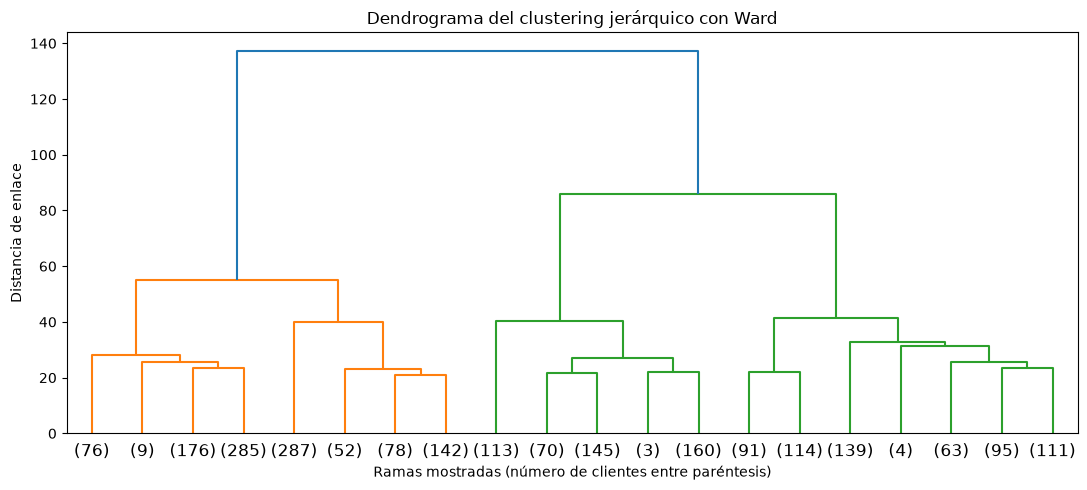

In [16]:
from scipy.cluster.hierarchy import dendrogram, linkage

datos_ward = X_preprocesado[columnas_modelo]
enlaces_ward = linkage(datos_ward, method="ward")

fig, ax = plt.subplots(figsize=(11, 5))

dendrogram(
    enlaces_ward,
    truncate_mode="lastp",
    p=20,
    show_leaf_counts=True,
    ax=ax,
)

ax.set_title("Dendrograma del clustering jerárquico con Ward")
ax.set_xlabel("Ramas mostradas (número de clientes entre paréntesis)")
ax.set_ylabel("Distancia de enlace")
plt.tight_layout()
plt.show()

El dendrograma sugiere dos soluciones. Un corte a la altura de 110 da lugar a dos grupos, mientras que un corte a la altura de 70 produce tres. Comparamos el silhouette y los perfiles de ambas soluciones para valorar si el tercer grupo permite distinguir un patrón de compra adicional.

In [29]:
from scipy.cluster.hierarchy import cut_tree

resultados_ward = []
etiquetas_ward = {}

for k in [2, 3]:
    etiquetas = cut_tree(enlaces_ward, n_clusters=k).ravel()
    etiquetas_ward[k] = etiquetas
    tamanos = pd.Series(etiquetas).value_counts().sort_index()

    resultados_ward.append({
        "k": k,
        "silhouette_referencia": silhouette_score(X_preprocesado, etiquetas),
        "clientes_por_grupo": tamanos.tolist(),
    })

tabla_ward = pd.DataFrame(resultados_ward)
tabla_ward.round({"silhouette_referencia": 4})

,k,silhouette_referencia,clientes_por_grupo
0,2,0.2117,"[1108, 1105]"
1,3,0.1821,"[617, 1105, 491]"


Según el silhouette, el de dos grupos sigue funcionando mejor. Veamos de todas formas que perfiles aportan los 2 y 3 clusters para ver con cual nos quedamos.

In [30]:
perfiles_por_k = {}

for k in [2, 3]:
    perfiles_por_k[k] = (
        df_segmentos.assign(cluster_ward=etiquetas_ward[k])
        .groupby("cluster_ward")
        .agg(
            clientes=("ID", "size"),
            gasto_mediano=("GastoTotal", "median"),
            recencia_mediana=("Recency", "median"),
            compras_web_mediana=("NumWebPurchases", "median"),
            compras_catalogo_mediana=("NumCatalogPurchases", "median"),
            compras_tienda_mediana=("NumStorePurchases", "median"),
            compras_descuento_mediana=("NumDealsPurchases", "median"),
        )
        .sort_values("gasto_mediano")
    )

pd.concat(perfiles_por_k, names=["k", "cluster_ward"]).round(1)

clientes  gasto_mediano  recencia_mediana  \
k cluster_ward                                              
2 1                 1105           69.0              48.0   
  0                 1108         1043.5              51.0   
3 1                 1105           69.0              48.0   
  2                  491          731.0              54.0   
  0                  617         1244.0              47.0   

                compras_web_mediana  compras_catalogo_mediana  \
k cluster_ward                                                  
2 1                             2.0                       0.0   
  0                             6.0                       4.0   
3 1                             2.0                       0.0   
  2                             6.0                       3.0   
  0                             5.0                       5.0   

                compras_tienda_mediana  compras_descuento_mediana  
k cluster_ward                                                     
2 1                                3.0                        2.0  
  0                                8.0                        2.0  
3 1                                3.0                        2.0  
  2                                7.0                        4.0  
  0                                9.0                        1.0

En Ward, el silhouette es mayor con dos grupos. El corte en tres grupos conserva el perfil de menor gasto (1.105 clientes, con un gasto mediano de 69) y divide a los otros 1.108 clientes en dos perfiles de compra:

- Gasto intermedio (491 clientes). El gasto mediano es de 731. Este grupo registra una mediana de 6 compras por web y 4 con descuento, frente a 5 y 1, respectivamente, en el grupo de mayor gasto.
- Gasto alto (617 clientes). El gasto mediano es de 1.244. Este grupo compra más por catálogo y en tienda física, con medianas de 5 y 9 compras, respectivamente.

Elegimos tres grupos para interpretar los hábitos de compra. El corte permite distinguir un perfil intermedio con más compras con descuento y otro de mayor gasto con más compras por catálogo y en tienda, y registra menos compras con descuento que el grupo de gasto intermedio.

In [31]:
respuesta_ward = (
    df_segmentos.assign(cluster_ward=etiquetas_ward[3])
    .groupby("cluster_ward")["Response"]
    .agg(clientes="size", aceptaron="sum")
    .reindex(perfiles_por_k[3].index)
)

respuesta_ward["aceptacion_pct"] = (
    100 * respuesta_ward["aceptaron"] / respuesta_ward["clientes"]
)

respuesta_ward.round(1)

,clientes,aceptaron,aceptacion_pct
cluster_ward,,,
1,1105,97,8.8
2,491,88,17.9
0,617,148,24.0


La aceptación de la campaña parece aumentar junto al nivel de gasto. El grupo de menor gasto acepto un 9.1%, frente al 26.6% del grupo de más gasto. El grupo intermedio queda más cerca del menor grupo en cuanto a la aceptación, pero su forma de comprar es distinta, ya que compran muchos más artículos en descuento. 

Ahora emplearemos DBSCAN haciendo una búsqueda de un epsilon razonable. Vamos a fijar de manera arbitraria min_samples a 10 para que un cliente se considere un núcleo si hay al menos 10 clientes alrededor de él (incluyéndose).

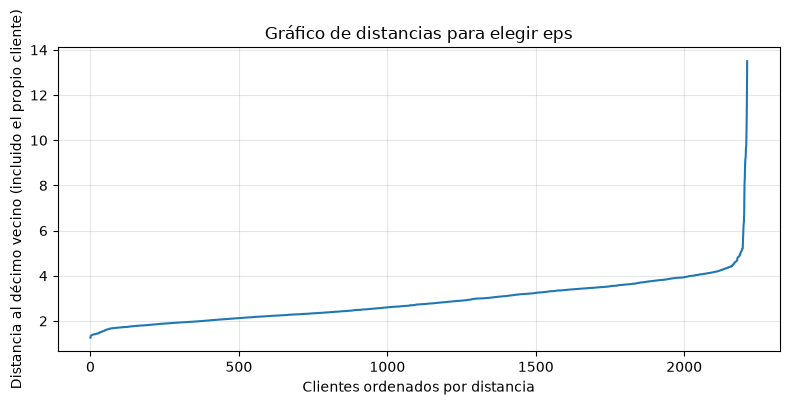

In [20]:
from sklearn.neighbors import NearestNeighbors

datos_dbscan = X_preprocesado[columnas_modelo]
min_samples_dbscan = 10

vecinos = NearestNeighbors(
    n_neighbors=min_samples_dbscan,
    metric="euclidean"
).fit(datos_dbscan)

distancias, _ = vecinos.kneighbors(datos_dbscan)
distancia_vecino = np.sort(distancias[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(distancia_vecino)
plt.xlabel("Clientes ordenados por distancia")
plt.ylabel("Distancia al décimo vecino (incluido el propio cliente)")
plt.title("Gráfico de distancias para elegir eps")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

A partir de 4 y 5, empieza a subir rápidamente, sin establecer un codo claro. Vamos a probar radios al rededor de esa zona. Un radio pequeño puede hacer que se tomen muchos clientes como ruido, y uno grande puede agrupar casi todos en un mismo cluster.

In [32]:
from sklearn.cluster import DBSCAN

resultados_dbscan = []
etiquetas_dbscan = {}

for eps in [2.5, 3.0, 3.5, 4.0, 4.5, 5.0]:
    etiquetas = DBSCAN(
        eps=eps,
        min_samples=min_samples_dbscan,
        metric="euclidean",
    ).fit_predict(datos_dbscan)

    etiquetas_dbscan[eps] = etiquetas
    ruido = etiquetas == -1
    tamanos = pd.Series(etiquetas[~ruido]).value_counts()

    resultados_dbscan.append({
        "eps": eps,
        "grupos": len(tamanos),
        "clientes_por_grupo": tamanos.tolist(),
        "clientes_ruido": ruido.sum(),
        "ruido_pct": 100 * ruido.mean(),
    })

tabla_dbscan = pd.DataFrame(resultados_dbscan)
tabla_dbscan.round({"ruido_pct": 1})

,eps,grupos,clientes_por_grupo,clientes_ruido,ruido_pct
0,2.5,1,[1187],1026,46.4
1,3.0,2,"[1596, 11]",606,27.4
2,3.5,1,[1998],215,9.7
3,4.0,1,[2172],41,1.9
4,4.5,1,[2194],19,0.9
5,5.0,1,[2202],11,0.5


Vemos que, con min_samples = 10, DBSCAN encuentra un grupo principal para todos los radios probados. Con eps = 3,0 aparece también un grupo de 11 clientes, pero un 27,0 % de los registros queda como ruido. Al subir a eps = 4,0, el ruido baja al 1,8 %, aunque quedan 2.199 clientes en un único grupo. Por ello, con estos parámetros, DBSCAN aporta más para detectar clientes en zonas poco densas que para definir varios segmentos que podamos comparar.

Pero es verdad que solo probamos con min samples = 10. Vamos a probar con distintos valores para hacer una comparación. Con valores pequeños, lo normal es que no se formen grupos en zonas densas, aunque estos pueden ser pequeños.

In [33]:
resultados_sensibilidad = []

for min_samples in [5, 10, 15, 20]:
    for eps in [2.5, 2.75, 3.0, 3.25, 3.5, 4.0, 4.5, 5.0]:
        etiquetas = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric="euclidean",
        ).fit_predict(datos_dbscan)

        ruido = etiquetas == -1
        tamanos = pd.Series(etiquetas[~ruido]).value_counts()

        resultados_sensibilidad.append({
            "min_samples": min_samples,
            "eps": eps,
            "grupos": len(tamanos),
            "clientes_por_grupo": tamanos.tolist(),
            "ruido_pct": 100 * ruido.mean(),
        })

tabla_sensibilidad = pd.DataFrame(resultados_sensibilidad)
tabla_sensibilidad.round({"ruido_pct": 1})

,min_samples,eps,grupos,clientes_por_grupo,ruido_pct
0,5,2.50,5,"[1260, 10, 6, 5, 5]",41.9
1,5,2.75,2,"[1495, 2]",32.4
2,5,3.00,1,[1693],23.5
3,5,3.25,3,"[1893, 5, 3]",14.1
4,5,3.50,1,[2064],6.7
5,5,4.00,1,[2177],1.6
6,5,4.50,1,[2195],0.8
7,5,5.00,1,[2202],0.5
8,10,2.50,1,[1187],46.4
9,10,2.75,1,[1387],37.3


Pese a la gran cantidad de valores que hemos probado, se sigue el mismo patrón que antes, un grupo dominante y cuando aparecen otros, son muy reducidos.

## Evaluación e interpretación de los resultados

In [35]:
kmeans_2 = tabla_k.loc[
    (tabla_k["conjunto"] == "25 candidatas") & (tabla_k["k"] == 2)
].iloc[0]

comparacion = [{
    "metodo": "K-means",
    "grupos": 2,
    "clientes_por_grupo": sorted(perfiles["clientes"].tolist(), reverse=True),
    "silhouette_referencia": kmeans_2["silhouette_referencia"],
}]

for fila in tabla_ward.itertuples(index=False):
    comparacion.append({
        "metodo": "Ward",
        "grupos": fila.k,
        "clientes_por_grupo": sorted(fila.clientes_por_grupo, reverse=True),
        "silhouette_referencia": fila.silhouette_referencia,
    })

tabla_comparacion = pd.DataFrame(comparacion)

print("Comparación de K-means y Ward")
display(tabla_comparacion.round({"silhouette_referencia": 4}))

resumen_dbscan = tabla_sensibilidad.assign(
    segundo_grupo=tabla_sensibilidad["clientes_por_grupo"].apply(
        lambda tamanos: tamanos[1] if len(tamanos) > 1 else 0
    )
)

resumen_dbscan = (
    resumen_dbscan
    .sort_values(["segundo_grupo", "ruido_pct"], ascending=[False, True])
    .head(5)
    .drop(columns="segundo_grupo")
    .reset_index(drop=True)
)

print("Resumen de DBSCAN")
display(resumen_dbscan.round({"eps": 2, "ruido_pct": 1}))

Comparación de K-means y Ward


,metodo,grupos,clientes_por_grupo,silhouette_referencia
0,K-means,2,"[1280, 933]",0.2541
1,Ward,2,"[1108, 1105]",0.2117
2,Ward,3,"[1105, 617, 491]",0.1821


Resumen de DBSCAN


,min_samples,eps,grupos,clientes_por_grupo,ruido_pct
0,10,3.00,2,"[1596, 11]",27.4
1,5,2.50,5,"[1260, 10, 6, 5, 5]",41.9
2,5,3.25,3,"[1893, 5, 3]",14.1
3,5,2.75,2,"[1495, 2]",32.4
4,5,5.00,1,[2202],0.5


Vemos que K-means con dos clusters obtiene el mayor silhouette. Los dos grupos tienen 1.300 y 940 aproximadamente. Esta es la solución que elegiríamos para resumir los perfiles de compra, aunque la separación entre los grupos no es del todo buena.

Con Ward, el corte en tres grupos tiene un silhouette menor, pero aporta más detalle. Separa a los clientes de gasto intermedio, que hacen más compras con descuento, de los de gasto alto, que compran más por catálogo y en tienda. También vemos que la aceptación de la campaña aumenta con el nivel de gasto, del 9,1 % en el primer grupo al 26,6 % en el de mayor gasto.

En DBSCAN, al variar eps y min_samples seguimos obteniendo un grupo dominante. Cuando aparece un segundo grupo, tiene como máximo 11 clientes. La configuración con menos ruido deja al 0,6 % fuera, pero reúne a los otros 2.227 clientes en un solo grupo. Con los parámetros probados, K-means y Ward nos resultaron más útiles para comparar hábitos de compra.

Nos quedamos con Ward y tres grupos. Aunque K-means obtuvo un silhouette mayor, Ward distingue un perfil intermedio que compra más con descuento y otro de gasto alto que compra más por catálogo y en tienda. Con los parámetros probados, DBSCAN tendió a formar un único grupo dominante.

Ahora nos centraremos en estos tres grupos. Veamos que variables los distinguen con un mapa de calor, haciendo una interpretación global. Esto se asimila la idea de analizar los centroides y comparar las variables entre grupos

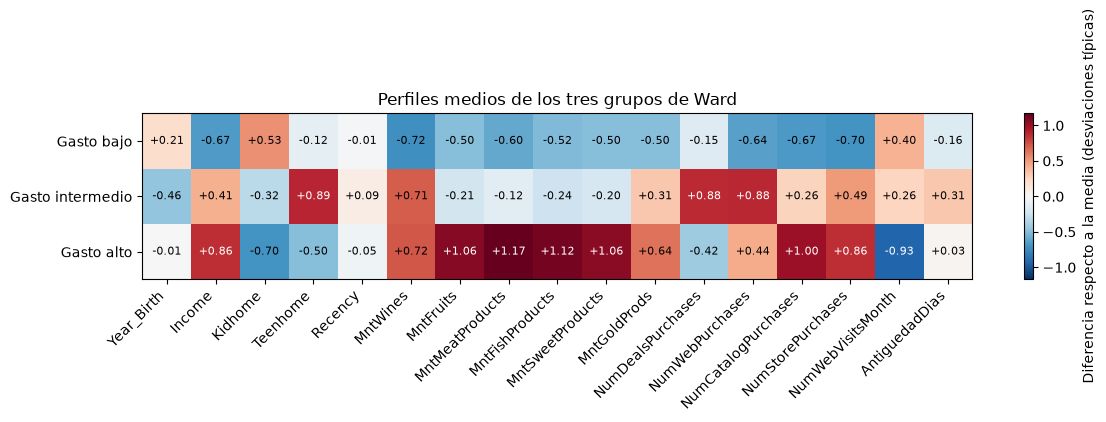

In [37]:
perfiles_globales_ward = (
    X_preprocesado[columnas_escalar]
    .assign(grupo=etiquetas_ward[3])
    .groupby("grupo")
    .mean()
    .reindex(perfiles_por_k[3].index)
)

fig, ax = plt.subplots(figsize=(12, 3.5))
limite = perfiles_globales_ward.abs().to_numpy().max()

mapa = ax.imshow(
    perfiles_globales_ward,
    cmap="RdBu_r",
    vmin=-limite,
    vmax=limite,
    aspect="auto",
)

for i, fila in enumerate(perfiles_globales_ward.to_numpy()):
    for j, valor in enumerate(fila):
        color = "white" if abs(valor) > 0.65 * limite else "black"
        ax.text(
            j, i, f"{valor:+.2f}",
            ha="center", va="center",
            color=color, fontsize=8,
        )

ax.set_xticks(
    range(len(perfiles_globales_ward.columns)),
    perfiles_globales_ward.columns,
    rotation=45,
    ha="right",
)
ax.set_yticks(range(3), ["Gasto bajo", "Gasto intermedio", "Gasto alto"])
ax.set_title("Perfiles medios de los tres grupos de Ward")
fig.colorbar(mapa, ax=ax, label="Diferencia respecto a la media (desviaciones típicas)")
plt.tight_layout()
plt.show()

Vemos que el grupo de gasto bajo compra menos por todos los canales, aunque visita la web más que la media. El grupo intermedio destaca por las compras con descuento y por web, mientras que el de gasto alto sobresale en casi todas las categorías de gasto y en las compras por catálogo y en tienda.

La recencia apenas cambia entre los grupos. El gráfico ayuda a entender por qué elegimos tres grupos con Ward: el perfil intermedio se distingue por cómo compra, además de por cuánto gasta.